# IADS5 · TP integrador — Ortelana Textil
### Actividad 01 · Framing, EDA y split de datos

**Integrantes del grupo:** Camila Belén Capua, Franco Salama, Juan Pablo Ruax Debruijn, Lorena Wajchman, Tomas Rossi y Miguel Ángel Tadakuma  
**Comisión:** [Completar]  
**Repositorio GitHub:** https://github.com/francosalama/paa-integrador-ortelana  
**Fecha:** 17/11/2026

## Reglas comunes y decisiones de adaptación

- Dataset: **Ortelana Textil**. Verificá que cumpla los requisitos del TP: **≥500 filas**, variables numéricas y categóricas, target claro y ausencia de proxies directos del target.
- **Problema principal:** clasificación multiclase de `Format_Reporte` (si el CSV contiene esa columna). Usá el significado de las clases que surja de los datos/documentación; no inventes interpretaciones.
- **Problema secundario de regresión:** para las actividades que lo requieren, proponé un **target numérico legítimo** disponible en Ortelana, por ejemplo `Metros1` *solo si su predicción es justificable*. Excluí ese target de las features y evitá variables que lo revelen directa o indirectamente. Documentá las decisiones. **No conviertas códigos arbitrarios de categorías en una variable continua por conveniencia.**
- Reservá **20% para test** una sola vez (`random_state=42`; estratificá el target de clasificación). Conservá y reutilizá los mismos índices para comparar modelos dentro de cada problema. Para el problema de regresión, explicá la partición y su relación con el split original.
- No utilices el test para elegir hiperparámetros: seleccioná con validación cruzada sobre entrenamiento. El enunciado original solicita métricas de test en varias actividades; reportalas cuando corresponda, pero reconocé que **consultarlo repetidamente puede sesgar las decisiones**.
- Desde la actividad 9, el preprocesamiento supervisado debe integrarse en un `Pipeline` y validarse sin data leakage. Para clustering, no uses el target como feature.
- Justificá todas las decisiones. Cada TODO es **abierto**: debés escribir el código y explicar por qué lo elegiste.

**Dependencias sugeridas:** pandas, numpy, matplotlib, seaborn (opcional), scikit-learn, xgboost, scipy, joblib. Registrá versiones en la entrega final.

## Preparación y reproducibilidad

Ubicá el CSV junto al notebook (o indicá una ruta relativa reproducible). Confirmá nombres reales de columnas, tipos y disponibilidad de librerías. Documentá cualquier adaptación necesaria.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # avisos de versión de librerías

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

df = pd.read_csv("ventas_historicas_ortelana_argentina.csv")   # ruta relativa: el CSV está junto al notebook
metros_cols = [f"Metros{i}" for i in range(1, 13)]

print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__)
print("Dimensiones:", df.shape)
print("Columnas:", df.columns.tolist())

pandas 3.0.5 | scikit-learn 1.9.0 | xgboost 3.4.1
Dimensiones: (3285, 16)
Columnas: ['Sucursal_ID', 'Año', 'Tela_ID', 'Format_Reporte', 'Metros1', 'Metros2', 'Metros3', 'Metros4', 'Metros5', 'Metros6', 'Metros7', 'Metros8', 'Metros9', 'Metros10', 'Metros11', 'Metros12']


**Registro de decisiones compartidas**

- **Ruta del dataset:** `ventas_historicas_ortelana_argentina.csv`, ruta relativa en la misma carpeta que el notebook. Tiene 3285 filas y 16 columnas: `Sucursal_ID`, `Año`, `Tela_ID`, `Format_Reporte` y `Metros1`…`Metros12`. Cumple los requisitos del TP: ≥500 filas, variables numéricas y categóricas, y un target claro.
- **Target principal de clasificación y significado:** `Format_Reporte`, con 4 clases. Según la descripción del dataset, indica la **granularidad temporal** con la que la sucursal consolidó las ventas de esa fila: **M = mensual** (12 períodos), **B = bimestral** (6), **S = semestral** (2) y **C = ciclo estacional** (2). Lo verificamos con los datos: cada formato trae exactamente esa cantidad de columnas de metros con dato. Predecirlo significa anticipar con qué granularidad reporta una sucursal las ventas de una tela.
- **Target secundario de regresión y justificación:** `Metros2`, los metros vendidos en el segundo período del reporte. Es una cantidad continua genuina, medida en metros, y está completa en todas las filas. La predecimos a partir del primer período (`Metros1`) y del contexto (`Sucursal_ID`, `Tela_ID`, `Año`). El caso de uso es anticipar el volumen del período siguiente cuando ya se conoce el primero. Es la misma tarea complementaria que se usa en la cursada.
- **Features incluidas/excluidas y motivos:**
  - **Clasificación:** usamos `Sucursal_ID` y `Tela_ID` como identificadores categóricos (one-hot), y `Año`, `Metros1` y `Metros2` como numéricas.
  - **Excluimos `Metros3`–`Metros12`:** que estén presentes o vacías revela la clase de forma determinística. Es un proxy directo del target (ver la Actividad 01).
  - **Regresión:** se excluyen `Metros2`, que es el target, y `Metros3`–`Metros12`. También queda afuera `Format_Reporte`, para no mezclar las tareas.
- **Identificadores de train/test persistidos en:** `particion_train_test.csv` (fila → train/test). Es una partición 80/20 estratificada por `Format_Reporte` con `random_state=42`. La regresión reutiliza exactamente los mismos índices.
- **Riesgos de fuga temporal, por sucursal o por columnas proxy:**
  1. **Proxy:** el patrón de faltantes de `Metros3`–`Metros12`, que por eso se excluyen.
  2. **Dependencia entre registros:** el formato es constante para cada par (Sucursal, Tela) en todos los años (0 de 360 pares cambian). Con la partición aleatoria, el 100% de los pares de test también aparece en train. Las métricas miden generalización a otros años de pares conocidos, no a sucursales o telas nuevas.
  3. **Temporal:** el split aleatorio mezcla años, así que se entrena con años posteriores a algunos registros de test.
  4. **Escala:** según la descripción del dataset, `Metros1`–`Metros12` reparten el volumen anual entre los períodos del formato. Por eso `Metros1` y `Metros2` son mayores en los formatos de 2 períodos (un semestre o ciclo junta más metros que un mes). Parte de su poder predictivo viene de esa construcción del reporte.

## Actividad 01 · Framing, EDA y split de datos

**Qué se espera:** Definí el problema, explorá filas, tipos, faltantes y distribución del target; reservá 20% para test y construí la baseline de clasificación (y la de regresión cuando corresponda).

**Evidencia a entregar:** EDA documentada; partición persistida y reproducible; predicciones de baseline.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [2]:
# 1.1 Primer vistazo: filas, tipos y faltantes
display(df.head())

resumen = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "faltantes": df.isna().sum(),
    "% faltantes": (df.isna().mean() * 100).round(1),
    "valores únicos": df.nunique(),
})
display(resumen)

print("Filas duplicadas:", df.duplicated().sum())
print("Máximo de filas por (Sucursal, Año, Tela):", df.groupby(["Sucursal_ID", "Año", "Tela_ID"]).size().max())

# Combinaciones posibles: 12 sucursales x 10 años x 30 telas
posibles = df["Sucursal_ID"].nunique() * df["Año"].nunique() * df["Tela_ID"].nunique()
faltantes = posibles - len(df)
print(f"Combinaciones posibles: {posibles} | presentes: {len(df)} | faltantes: {faltantes} ({faltantes / posibles:.2%})")

,Sucursal_ID,Año,Tela_ID,Format_Reporte,Metros1,Metros2,Metros3,Metros4,Metros5,Metros6,Metros7,Metros8,Metros9,Metros10,Metros11,Metros12
0,1,2016,TELA-001,S,5826.63,5919.77,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2016,TELA-002,C,2747.21,2081.75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,2016,TELA-003,S,3711.95,3752.10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1,2016,TELA-004,B,1275.78,1798.45,1923.95,1861.88,1747.80,1233.24,NaN,NaN,NaN,NaN,NaN,NaN
4,1,2016,TELA-005,M,240.05,241.48,321.98,384.31,396.75,355.00,340.77,383.03,401.43,306.25,278.83,235.65


,tipo,faltantes,% faltantes,valores únicos
Sucursal_ID,int64,0,0.0,12
Año,int64,0,0.0,10
Tela_ID,str,0,0.0,30
Format_Reporte,str,0,0.0,4
Metros1,float64,0,0.0,3258
Metros2,float64,0,0.0,3253
Metros3,float64,1788,54.4,1479
Metros4,float64,1788,54.4,1479
Metros5,float64,1788,54.4,1486
Metros6,float64,1788,54.4,1480


Filas duplicadas: 0
Máximo de filas por (Sucursal, Año, Tela): 1
Combinaciones posibles: 3600 | presentes: 3285 | faltantes: 315 (8.75%)


In [3]:
# 1.2 Estadísticos descriptivos
print("Sucursales:", df["Sucursal_ID"].nunique(), "| Años:", df["Año"].min(), "a", df["Año"].max(),
      "| Telas:", df["Tela_ID"].nunique())
df[["Año"] + metros_cols].describe().T.round(2)

Sucursales: 12 | Años: 2016 a 2025 | Telas: 30


,count,mean,std,min,25%,50%,75%,max
Año,3285.0,2020.50,2.87,2016.00,2018.00,2020.00,2023.00,2025.00
Metros1,3285.0,960.68,1103.53,0.47,195.65,536.17,1376.17,9487.04
Metros2,3285.0,956.71,1015.76,0.47,238.34,654.98,1319.06,9293.61
Metros3,1497.0,399.99,373.74,0.63,152.36,291.97,548.76,3001.36
Metros4,1497.0,440.14,386.83,0.75,177.78,340.73,597.60,3479.49
Metros5,1497.0,446.29,408.09,0.69,188.96,341.61,594.22,6266.63
Metros6,1497.0,366.17,321.38,0.67,164.98,281.15,477.32,4745.57
Metros7,765.0,308.05,249.57,0.70,142.57,247.54,397.02,1800.73
Metros8,765.0,339.23,261.18,0.82,162.42,267.57,438.21,1492.26
Metros9,765.0,344.84,283.17,0.78,165.71,276.44,431.14,2450.38


,registros,%
Format_Reporte,,
B,732,22.3
C,860,26.2
M,765,23.3
S,928,28.2


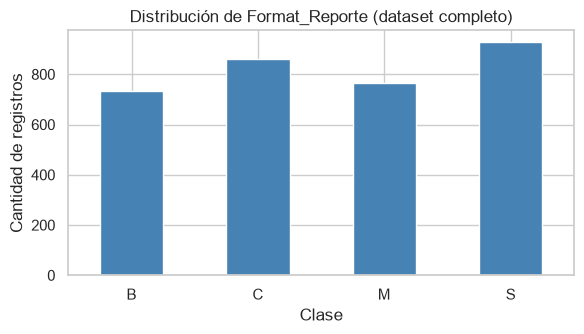

In [4]:
# 1.3 Distribución del target principal
conteo = df["Format_Reporte"].value_counts().sort_index()
porcentaje = (df["Format_Reporte"].value_counts(normalize=True).sort_index() * 100).round(1)
display(pd.DataFrame({"registros": conteo, "%": porcentaje}))

ax = conteo.plot(kind="bar", color="steelblue", rot=0, figsize=(6, 3.5))
ax.set_title("Distribución de Format_Reporte (dataset completo)")
ax.set_xlabel("Clase")
ax.set_ylabel("Cantidad de registros")
plt.tight_layout()
plt.show()

In [5]:
# 1.4 Cantidad de columnas de metros con dato según el formato
# Coincide con la descripción del dataset: M mensual (12 períodos), B bimestral (6),
# S semestral y C ciclo estacional (2). Si el modelo viera Metros3..Metros12 (o cuántas
# están vacías), "leería" la clase: por eso esas columnas se excluyen.
periodos_con_dato = df[metros_cols].notna().sum(axis=1)
pd.crosstab(df["Format_Reporte"], periodos_con_dato.rename("Períodos con dato"))

Períodos con dato,2,6,12
Format_Reporte,,,
B,0,732,0
C,860,0,0
M,0,0,765
S,928,0,0


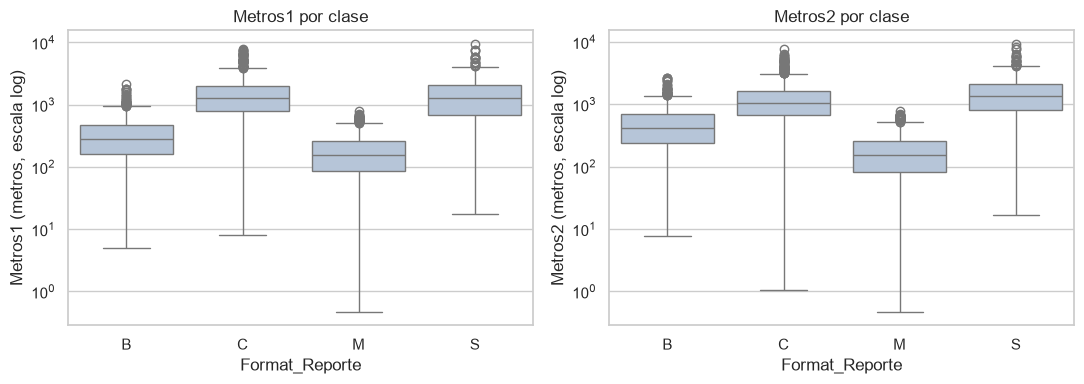

Correlación Metros1-Metros2: 0.906


,Metros1,Metros2
Format_Reporte,,
B,284.265,416.365
C,1287.310,1051.415
M,155.150,156.070
S,1274.790,1333.510


In [6]:
# 1.5 Metros1 y Metros2 por clase (escala log porque las distribuciones son muy asimétricas)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ["Metros1", "Metros2"]):
    sns.boxplot(data=df, x="Format_Reporte", y=col, order=["B", "C", "M", "S"], ax=ax, color="lightsteelblue")
    ax.set_yscale("log")
    ax.set_title(f"{col} por clase")
    ax.set_ylabel(f"{col} (metros, escala log)")
plt.tight_layout()
plt.show()

print("Correlación Metros1-Metros2:", round(df["Metros1"].corr(df["Metros2"]), 3))
df.groupby("Format_Reporte")[["Metros1", "Metros2"]].median()

In [7]:
# 1.6 ¿Cambia el formato para una misma sucursal y tela a lo largo de los años?
clases_por_par = df.groupby(["Sucursal_ID", "Tela_ID"])["Format_Reporte"].nunique()
print("Pares (Sucursal, Tela):", len(clases_por_par))
print("Pares que cambian de formato en algún año:", (clases_por_par > 1).sum())

pd.crosstab(df["Sucursal_ID"], df["Format_Reporte"])

Pares (Sucursal, Tela): 360
Pares que cambian de formato en algún año: 0


Format_Reporte,B,C,M,S
Sucursal_ID,,,,
1,50,50,100,100
2,80,70,70,80
3,53,66,78,65
4,75,69,61,60
5,64,79,64,63
6,79,65,68,54
7,70,67,46,94
8,66,102,45,65
9,34,110,57,73


In [8]:
# 1.7 Partición única 80/20 estratificada (random_state=42) y guardado de la partición
from sklearn.model_selection import train_test_split

target = "Format_Reporte"
features = ["Sucursal_ID", "Tela_ID", "Año", "Metros1", "Metros2"]   # sin Metros3..Metros12 (proxy)

train, test = train_test_split(df, test_size=0.2, stratify=df[target], random_state=RANDOM_STATE)
X_train, X_test = train[features], test[features]
y_train, y_test = train[target], test[target]

# Regresión de Metros2: mismas filas de train y test
features_reg = ["Sucursal_ID", "Tela_ID", "Año", "Metros1"]
Xr_train, Xr_test = train[features_reg], test[features_reg]
yr_train, yr_test = train["Metros2"], test["Metros2"]

# Guardar qué fila es train y cuál es test, para reutilizar la misma partición en todas las actividades
particion = pd.Series("train", index=df.index, name="particion")
particion[test.index] = "test"
particion.rename_axis("fila").to_csv("particion_train_test.csv")

print("Train:", train.shape, "| Test:", test.shape)
display(pd.DataFrame({"train %": y_train.value_counts(normalize=True) * 100,
                      "test %": y_test.value_counts(normalize=True) * 100}).round(1))

# ¿Cuántas filas de test tienen su par (Sucursal, Tela) también en train?
pares_train = set(zip(train["Sucursal_ID"], train["Tela_ID"]))
en_train = [par in pares_train for par in zip(test["Sucursal_ID"], test["Tela_ID"])]
print(f"Filas de test cuyo par (Sucursal, Tela) también está en train: {np.mean(en_train):.1%}")

Train: (2628, 16) | Test: (657, 16)


,train %,test %
Format_Reporte,,
S,28.2,28.3
C,26.2,26.2
M,23.3,23.3
B,22.3,22.2


Filas de test cuyo par (Sucursal, Tela) también está en train: 100.0%


In [9]:
# 1.8 Baselines: clase más frecuente (clasificación) y media de train (regresión)
from sklearn.dummy import DummyClassifier, DummyRegressor

baseline_clf = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
baseline_reg = DummyRegressor(strategy="mean").fit(Xr_train, yr_train)

pred_base_clf = baseline_clf.predict(X_test)
pred_base_reg = baseline_reg.predict(Xr_test)
print("Baseline de clasificación: predice siempre", pred_base_clf[0])
print(f"Baseline de regresión: predice siempre {pred_base_reg[0]:.2f} m (media de Metros2 en train)")

pd.DataFrame({"Format_Reporte real": y_test, "pred. baseline": pred_base_clf,
              "Metros2 real": yr_test, "pred. baseline reg": pred_base_reg.round(2)}).head(8)

Baseline de clasificación: predice siempre S
Baseline de regresión: predice siempre 967.71 m (media de Metros2 en train)


,Format_Reporte real,pred. baseline,Metros2 real,pred. baseline reg
1127,M,S,308.44,967.71
365,C,S,2106.97,967.71
1109,C,S,1150.65,967.71
1318,S,S,1152.13,967.71
2583,C,S,773.20,967.71
1785,S,S,2657.14,967.71
983,C,S,2113.23,967.71
3001,C,S,577.63,967.71


### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- **EDA:** revisamos tipos, faltantes, duplicados, la granularidad del dataset y la distribución del target. Hay una fila por (Sucursal, Año, Tela) y no hay duplicados.
- **Registros faltantes:** hay 3285 de las 3600 combinaciones posibles (12 sucursales × 10 años × 30 telas). Faltan 315 filas (8,75%), que corresponden a los quiebres de stock que menciona la descripción del dataset (que habla de un 10–12%). No son valores faltantes dentro de las filas, sino filas ausentes, por lo que no hay nada que imputar en `Metros1` y `Metros2`.
- **Proxy en los faltantes:** el cruce entre el target y la cantidad de períodos con dato muestra que M (mensual) siempre trae 12 columnas, B (bimestral) siempre 6, y S (semestral) y C (ciclo estacional) siempre 2. La descripción del dataset lo confirma: el formato "determina qué columnas métricas contienen información y cuáles quedan vacías". Por eso usar `Metros3`–`Metros12`, o sus NaN, sería una fuga: el modelo "leería" la respuesta. Nos quedamos con `Metros1` y `Metros2`, que están completos en todas las filas.
- **Partición:** separamos el 20% para test una sola vez, estratificado y con `random_state=42`, y guardamos la asignación de cada fila en un CSV. La regresión de `Metros2` usa los mismos índices, porque `Metros2` no tiene faltantes y no se pierde ninguna fila. Así, la clasificación y la regresión ven exactamente el mismo train y el mismo test.
- **Baselines:** `DummyClassifier(most_frequent)`, que siempre predice "S", y `DummyRegressor(mean)`, que siempre predice 967,71 m.
- **Alternativa considerada:** un split agrupado por par (Sucursal, Tela) o temporal por `Año`. Lo dejamos documentado como riesgo porque la consigna pide un split aleatorio estratificado.

**Interpretación de los resultados:**
- **Target:** está bastante balanceado (S 28,2%, C 26,2%, M 23,3%, B 22,3%), así que la proporción se conserva casi igual en train y test.
- **Metros:** las distribuciones son muy asimétricas (medianas de 536 m y 655 m frente a máximos de ~9.500 m), y `Metros1` y `Metros2` tienen una correlación de 0,906.
- **Volumen por clase:** los formatos de 2 períodos (C y S) tienen medianas cercanas a 1.300 m, mientras que B (~284/416 m) y M (~155 m) son mucho menores. Es lo esperable: los metros reparten el volumen anual, así que un semestre o ciclo acumula más que un bimestre o un mes. El total anual, en cambio, es parecido en los cuatro formatos.
- **Sucursales:** todas reportan las 4 clases, aunque en proporciones distintas.

**Pregunta de análisis:** ¿Qué significa predecir `Format_Reporte` en Ortelana? ¿Qué riesgos de fuga o dependencia entre registros identificás?
- **Qué significa:** predecir con qué granularidad temporal (mensual, bimestral, semestral o ciclo estacional), y por lo tanto con cuántos períodos (12, 6 o 2), se reporta la venta de una tela en una sucursal, usando la sucursal, la tela, el año y el volumen de los dos primeros períodos.
- **Fuga por columnas:** `Metros3`–`Metros12` determinan la clase al 100%.
- **Dependencia entre registros:** ningún par (Sucursal, Tela) cambia de formato en 10 años, y el 100% de las filas de test tiene su par en train. Un modelo puede acertar "recordando" el par en lugar de aprender una regla general, así que las métricas serán optimistas si el uso real fueran sucursales o telas nuevas.
- **Riesgo de construcción:** `Metros1` y `Metros2` dependen de la longitud del período, que es parte de la definición del formato.

**Limitaciones o mejoras posibles:**
- La descripción del dataset aclara qué es cada formato, pero no cuándo se conoce cada variable en la operación ni qué diferencia operativa hay entre semestral y ciclo estacional (ambos tienen 2 períodos).
- Una evaluación complementaria con `GroupKFold` por par o una partición temporal (entrenar hasta 2023 y testear 2024–2025) mediría mejor la generalización.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]
